# Numerical Computation of Force, Velocity & Acceleration (数値解析による力・速度・加速度の計算)

A mass $M$ is pushed by a known, time-varying force $F(t)$. By Newton's second law:

$$a(t) = \frac{F(t)}{M}$$

Velocity and position follow by integrating acceleration and velocity in time:

$$v(t) = v_0 + \int_0^t a(t')\,dt' \qquad x(t) = x_0 + \int_0^t v(t')\,dt'$$

This notebook computes $v(t)$ and $x(t)$ from $a(t)$ using three numerical methods and checks each one against the exact closed-form solution (available because $F(t)$ is chosen simple enough to integrate by hand):

- **Euler's method** - steps the ODE $\dot v = a(t)$, $\dot x = v(t)$ forward in time
- **Trapezoidal rule** - integrates the *sampled* $a(t)$, $v(t)$ curves directly
- **Simpson's rule** - same, using a higher-order quadrature

All quantities are in **SI units**: force in newtons [N], mass in kilograms [kg], acceleration in [m/s²], velocity in [m/s], position in [m], time in [s]. Constant parameters are named in CAPITAL letters.

Reference: [Wikipedia - Euler method](https://en.wikipedia.org/wiki/Euler_method), [Wikipedia - Trapezoidal rule](https://en.wikipedia.org/wiki/Trapezoidal_rule), [Wikipedia - Simpson's rule](https://en.wikipedia.org/wiki/Simpson%27s_rule)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid, cumulative_simpson

# CONSTANTS (SI units)
M = 2.0              # mass [kg]
F_CONSTANT = 3.0     # steady component of the applied force [N]
F_AMPLITUDE = 10.0   # amplitude of the oscillating force component [N]
OMEGA = 2.0          # angular frequency of the oscillating force [rad/s]
V_INITIAL = 1.0      # initial velocity [m/s]
X_INITIAL = 0.5      # initial position [m]
T_START = 0.0        # [s]
T_END = 5.0          # [s]
N_STEPS = 500        # number of time steps used for the main demonstration

def force(t):
    # F(t) = F_CONSTANT + F_AMPLITUDE * sin(OMEGA * t)   [N]
    return F_CONSTANT + F_AMPLITUDE*np.sin(OMEGA*t)

def acceleration(t):
    # a(t) = F(t) / M   [m/s^2]  (Newton's second law)
    return force(t)/M

# --- Exact closed-form solution, used ONLY to validate the numerical methods ---
def v_exact(t):
    return V_INITIAL + (F_CONSTANT/M)*t + (F_AMPLITUDE/(M*OMEGA))*(1-np.cos(OMEGA*t))

def x_exact(t):
    return (X_INITIAL + V_INITIAL*t + (F_CONSTANT/(2*M))*t**2
            + (F_AMPLITUDE/(M*OMEGA))*t - (F_AMPLITUDE/(M*OMEGA**2))*np.sin(OMEGA*t))

t = np.linspace(T_START, T_END, N_STEPS+1)
dt = t[1]-t[0]
a_vals = acceleration(t)
f_vals = force(t)
print(f"N_STEPS={N_STEPS}, dt={dt:.5f} s")

N_STEPS=500, dt=0.01000 s


## 1. Euler's Method

Forward Euler steps the equations of motion directly, one time step $\Delta t$ at a time:

$$v_{i+1} = v_i + a(t_i)\,\Delta t \qquad x_{i+1} = x_i + v_i\,\Delta t$$

Local truncation error is $O(\Delta t^2)$ per step, giving a **global error of $O(\Delta t)$** - halving $\Delta t$ roughly halves the error.

In [2]:
def euler_integrate(t, a_vals, v0, x0):
    n = len(t)
    v = np.empty(n); x = np.empty(n)
    v[0], x[0] = v0, x0
    for i in range(n-1):
        step = t[i+1]-t[i]
        v[i+1] = v[i] + a_vals[i]*step
        x[i+1] = x[i] + v[i]*step
    return v, x

v_euler, x_euler = euler_integrate(t, a_vals, V_INITIAL, X_INITIAL)
print(f"Euler   : v({T_END})={v_euler[-1]:.6f} m/s   x({T_END})={x_euler[-1]:.6f} m")
print(f"Exact   : v({T_END})={v_exact(T_END):.6f} m/s   x({T_END})={x_exact(T_END):.6f} m")

Euler   : v(5.0)=13.111126 m/s   x(5.0)=37.346021 m
Exact   : v(5.0)=13.097679 m/s   x(5.0)=37.430026 m


## 2. Trapezoidal Rule

Instead of stepping the ODE, the trapezoidal rule integrates the *sampled* curve directly - approximating each interval as a trapezoid:

$$\int_{t_i}^{t_{i+1}} a(t')\,dt' \approx \frac{a(t_i)+a(t_{i+1})}{2}\,\Delta t$$

Accumulating this interval-by-interval gives $v(t)$; integrating the resulting $v(t)$ the same way gives $x(t)$. Global error is $O(\Delta t^2)$.

In [3]:
v_trap = V_INITIAL + cumulative_trapezoid(a_vals, t, initial=0)
x_trap = X_INITIAL + cumulative_trapezoid(v_trap, t, initial=0)

print(f"Trapezoidal : v({T_END})={v_trap[-1]:.6f} m/s   x({T_END})={x_trap[-1]:.6f} m")
print(f"Exact       : v({T_END})={v_exact(T_END):.6f} m/s   x({T_END})={x_exact(T_END):.6f} m")

Trapezoidal : v(5.0)=13.097526 m/s   x(5.0)=37.429564 m
Exact       : v(5.0)=13.097679 m/s   x(5.0)=37.430026 m


## 3. Simpson's Rule

Simpson's rule fits a parabola through each pair of intervals instead of a straight line, giving a much higher-order approximation:

$$\int_{t_i}^{t_{i+2}} a(t')\,dt' \approx \frac{\Delta t}{3}\Big(a(t_i)+4a(t_{i+1})+a(t_{i+2})\Big)$$

Global error is $O(\Delta t^4)$ - far more accurate than Euler or the trapezoidal rule for the same $\Delta t$.

In [4]:
v_simp = V_INITIAL + cumulative_simpson(a_vals, x=t, initial=0)
x_simp = X_INITIAL + cumulative_simpson(v_simp, x=t, initial=0)

print(f"Simpson : v({T_END})={v_simp[-1]:.6f} m/s   x({T_END})={x_simp[-1]:.6f} m")
print(f"Exact   : v({T_END})={v_exact(T_END):.6f} m/s   x({T_END})={x_exact(T_END):.6f} m")

Simpson : v(5.0)=13.097679 m/s   x(5.0)=37.430026 m
Exact   : v(5.0)=13.097679 m/s   x(5.0)=37.430026 m


## Visualization: Force, Acceleration, Velocity & Position

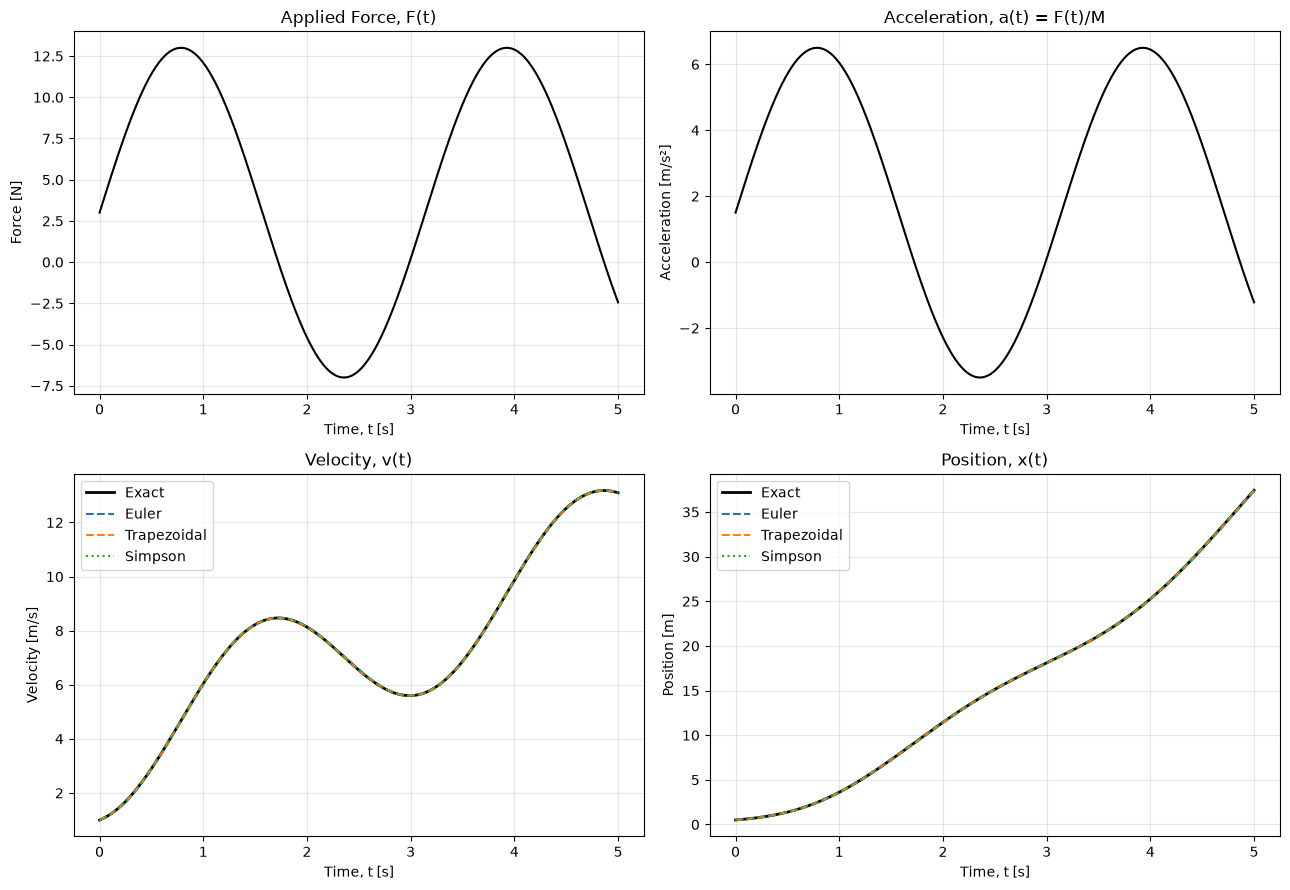

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13,9))

axes[0,0].plot(t, f_vals, color='k')
axes[0,0].set_title('Applied Force, F(t)')
axes[0,0].set_xlabel('Time, t [s]'); axes[0,0].set_ylabel('Force [N]')

axes[0,1].plot(t, a_vals, color='k')
axes[0,1].set_title('Acceleration, a(t) = F(t)/M')
axes[0,1].set_xlabel('Time, t [s]'); axes[0,1].set_ylabel('Acceleration [m/s²]')

axes[1,0].plot(t, v_exact(t), 'k-', lw=2, label='Exact')
axes[1,0].plot(t, v_euler, '--', label="Euler")
axes[1,0].plot(t, v_trap, '--', label='Trapezoidal')
axes[1,0].plot(t, v_simp, ':', label='Simpson')
axes[1,0].set_title('Velocity, v(t)')
axes[1,0].set_xlabel('Time, t [s]'); axes[1,0].set_ylabel('Velocity [m/s]')
axes[1,0].legend()

axes[1,1].plot(t, x_exact(t), 'k-', lw=2, label='Exact')
axes[1,1].plot(t, x_euler, '--', label='Euler')
axes[1,1].plot(t, x_trap, '--', label='Trapezoidal')
axes[1,1].plot(t, x_simp, ':', label='Simpson')
axes[1,1].set_title('Position, x(t)')
axes[1,1].set_xlabel('Time, t [s]'); axes[1,1].set_ylabel('Position [m]')
axes[1,1].legend()

for ax in axes.ravel():
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Accuracy comparison

In [6]:
from rich.console import Console
from rich.table import Table

console = Console()
table = Table(title=f"Final velocity/position at t={T_END} s  (N_STEPS={N_STEPS}, dt={dt:.4f} s)")
table.add_column("Method"); table.add_column("v [m/s]", justify="right"); table.add_column("|v error| [m/s]", justify="right")
table.add_column("x [m]", justify="right"); table.add_column("|x error| [m]", justify="right")

v_ref, x_ref = v_exact(T_END), x_exact(T_END)
for name, v_end, x_end in [("Euler", v_euler[-1], x_euler[-1]),
                            ("Trapezoidal", v_trap[-1], x_trap[-1]),
                            ("Simpson", v_simp[-1], x_simp[-1])]:
    table.add_row(name, f"{v_end:.6f}", f"{abs(v_end-v_ref):.3e}", f"{x_end:.6f}", f"{abs(x_end-x_ref):.3e}")
table.add_row("Exact", f"{v_ref:.6f}", "-", f"{x_ref:.6f}", "-", style="bold green")
console.print(table)

 Final velocity/position at t=5.0 s  (N_STEPS=500, dt=0.0100 s)  
┏━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ Method      ┃         v ┃  |v error| ┃         x ┃  |x error| ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ Euler       │ 13.111126 │  1.345e-02 │ 37.346021 │  8.401e-02 │
│ Trapezoidal │ 13.097526 │  1.533e-04 │ 37.429564 │  4.620e-04 │
│ Simpson     │ 13.097679 │  4.087e-09 │ 37.430026 │  9.298e-09 │
│ Exact       │ 13.097679 │          - │ 37.430026 │          - │
└─────────────┴───────────┴────────────┴───────────┴────────────┘

## Convergence study

Repeating the calculation at shrinking $\Delta t$ shows each method's theoretical order of accuracy: Euler's error falls linearly with $\Delta t$ ($O(\Delta t)$), the trapezoidal rule's falls quadratically ($O(\Delta t^2)$), and Simpson's rule falls with the 4th power ($O(\Delta t^4)$) - visible as parallel slopes on a log-log plot.

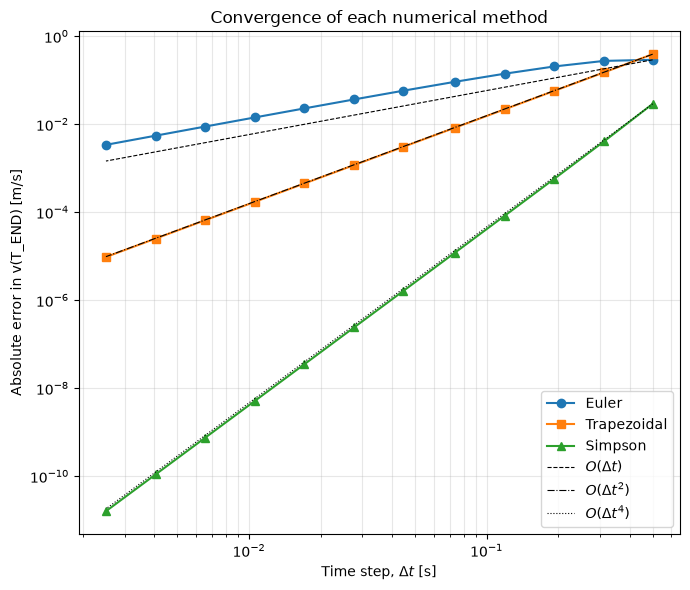

In [7]:
n_values = np.unique(np.geomspace(10, 2000, 12).astype(int))
n_values = n_values + (n_values % 2)   # Simpson needs an even number of intervals

euler_err, trap_err, simp_err, dt_values = [], [], [], []
for n in n_values:
    tt = np.linspace(T_START, T_END, n+1)
    aa = acceleration(tt)
    ddt = tt[1]-tt[0]

    v_e, _ = euler_integrate(tt, aa, V_INITIAL, X_INITIAL)
    v_t = V_INITIAL + cumulative_trapezoid(aa, tt, initial=0)
    v_s = V_INITIAL + cumulative_simpson(aa, x=tt, initial=0)

    dt_values.append(ddt)
    euler_err.append(abs(v_e[-1]-v_exact(T_END)))
    trap_err.append(abs(v_t[-1]-v_exact(T_END)))
    simp_err.append(abs(v_s[-1]-v_exact(T_END)))

dt_values = np.array(dt_values)

plt.figure(figsize=(7,6))
plt.loglog(dt_values, euler_err, 'o-', label='Euler')
plt.loglog(dt_values, trap_err, 's-', label='Trapezoidal')
plt.loglog(dt_values, simp_err, '^-', label='Simpson')

# reference slope lines (arbitrary offset, just to show the theoretical slope)
plt.loglog(dt_values, euler_err[0]*(dt_values/dt_values[0])**1, 'k--', lw=0.8, label=r'$O(\Delta t)$')
plt.loglog(dt_values, trap_err[0]*(dt_values/dt_values[0])**2, 'k-.', lw=0.8, label=r'$O(\Delta t^2)$')
plt.loglog(dt_values, simp_err[0]*(dt_values/dt_values[0])**4, 'k:', lw=0.8, label=r'$O(\Delta t^4)$')

plt.xlabel(r'Time step, $\Delta t$ [s]')
plt.ylabel('Absolute error in v(T_END) [m/s]')
plt.title('Convergence of each numerical method')
plt.legend()
plt.grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()

### Reference :
1. [Wikipedia - Euler method](https://en.wikipedia.org/wiki/Euler_method)
2. [Wikipedia - Trapezoidal rule](https://en.wikipedia.org/wiki/Trapezoidal_rule)
3. [Wikipedia - Simpson's rule](https://en.wikipedia.org/wiki/Simpson%27s_rule)